# Predicción de riesgo de entrega tardía - DataCo Smart Supply Chain
**Taller de Sistemas Inteligentes - Evaluación Unidad 4 y Final**

Metodología: **CRISP-ML(Q)**

1. Entendimiento del negocio y de los datos
2. Ingeniería de datos (preparación)
3. Ingeniería del modelo
4. Evaluación del modelo
5. Despliegue (exportación del modelo para el servicio de IA)
6. Monitoreo y mantenimiento (re-entrenamiento desde la API)

In [1]:
import json
import os
from datetime import datetime

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, RocCurveDisplay

## 1. Entendimiento del negocio y de los datos

**Problema de negocio:** DataCo necesita saber, al momento de registrar un pedido, si existe riesgo de que la entrega llegue tarde, para priorizar envíos o avisar al cliente.

**Tipo de problema:** Clasificación binaria supervisada. Variable objetivo: `Late_delivery_risk` (1 = entrega tardía, 0 = a tiempo).

**Criterio de éxito (calidad mínima aceptable):** Accuracy y F1 mayores a 0.70 y AUC mayor a 0.80 en el conjunto de prueba, superando claramente al modelo base (predecir siempre la clase mayoritaria).

In [2]:
df = pd.read_csv("../data/DataCoSupplyChainDataset.csv", encoding="latin-1")
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [3]:
print(df.shape)
df.info()

(180519, 53)
<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname              

In [4]:
descripcion = pd.read_csv("../data/DescriptionDataCoSupplyChain.csv", encoding="latin-1")
descripcion

,FIELDS,DESCRIPTION
0,Type,: Type of transaction made
1,Days for shipping (real),: Actual shipping days of the purchased product
2,Days for shipment (scheduled),: Days of scheduled delivery of the purchased...
3,Benefit per order,: Earnings per order placed
4,Sales per customer,: Total sales per customer made per customer
5,Delivery Status,: Delivery status of orders: Advance shipping...
6,Late_delivery_risk,: Categorical variable that indicates if send...
7,Category Id,: Product category code
8,Category Name,: Description of the product category
9,Customer City,: City where the customer made the purchase


In [5]:
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


In [6]:
print(df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicados:", df.duplicated().sum())

Customer Lname              8
Customer Zipcode            3
Order Zipcode          155679
Product Description    180519
dtype: int64


Duplicados: 0


In [7]:
df["Late_delivery_risk"].value_counts(normalize=True)

Late_delivery_risk
1    0.548291
0    0.451709
Name: proportion, dtype: float64

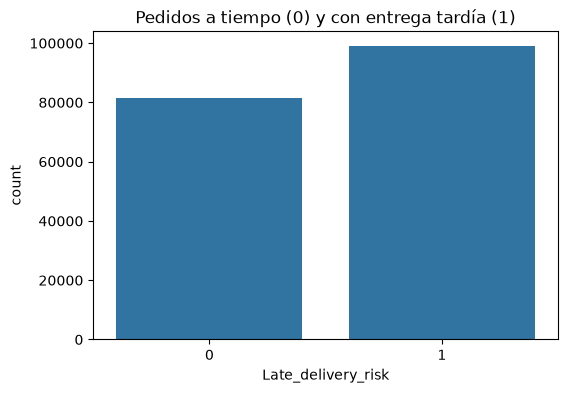

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Late_delivery_risk")
plt.title("Pedidos a tiempo (0) y con entrega tardía (1)")
plt.show()

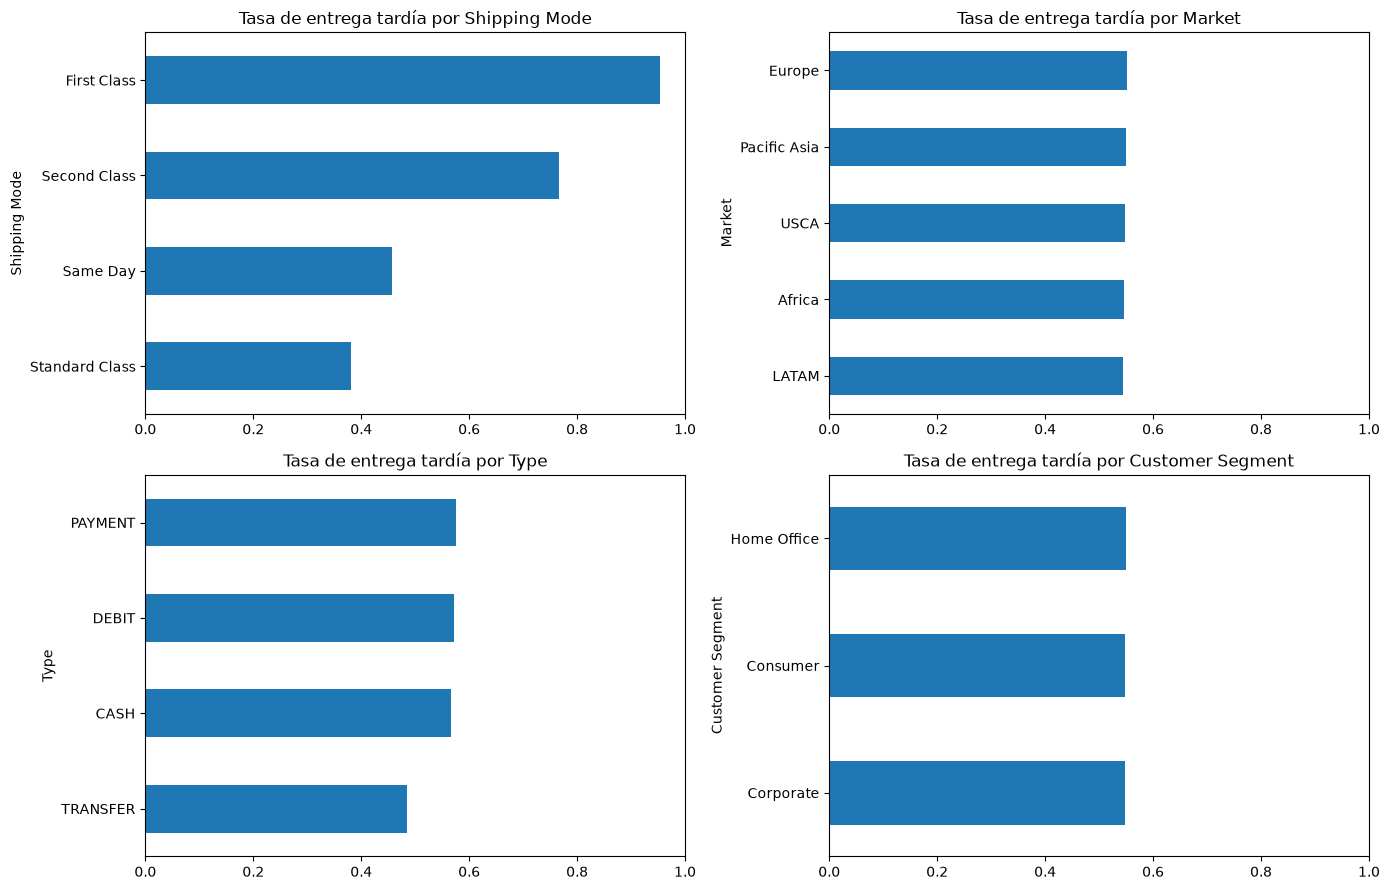

In [9]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))
for eje, columna in zip(ejes.flat, ["Shipping Mode", "Market", "Type", "Customer Segment"]):
    tasa = df.groupby(columna)["Late_delivery_risk"].mean().sort_values()
    tasa.plot(kind="barh", ax=eje, title=f"Tasa de entrega tardía por {columna}")
    eje.set_xlim(0, 1)
plt.tight_layout()
plt.show()

In [10]:
pd.crosstab(df["Shipping Mode"], df["Late_delivery_risk"], normalize="index").round(3)

Late_delivery_risk,0,1
Shipping Mode,,
First Class,0.047,0.953
Same Day,0.543,0.457
Second Class,0.234,0.766
Standard Class,0.619,0.381


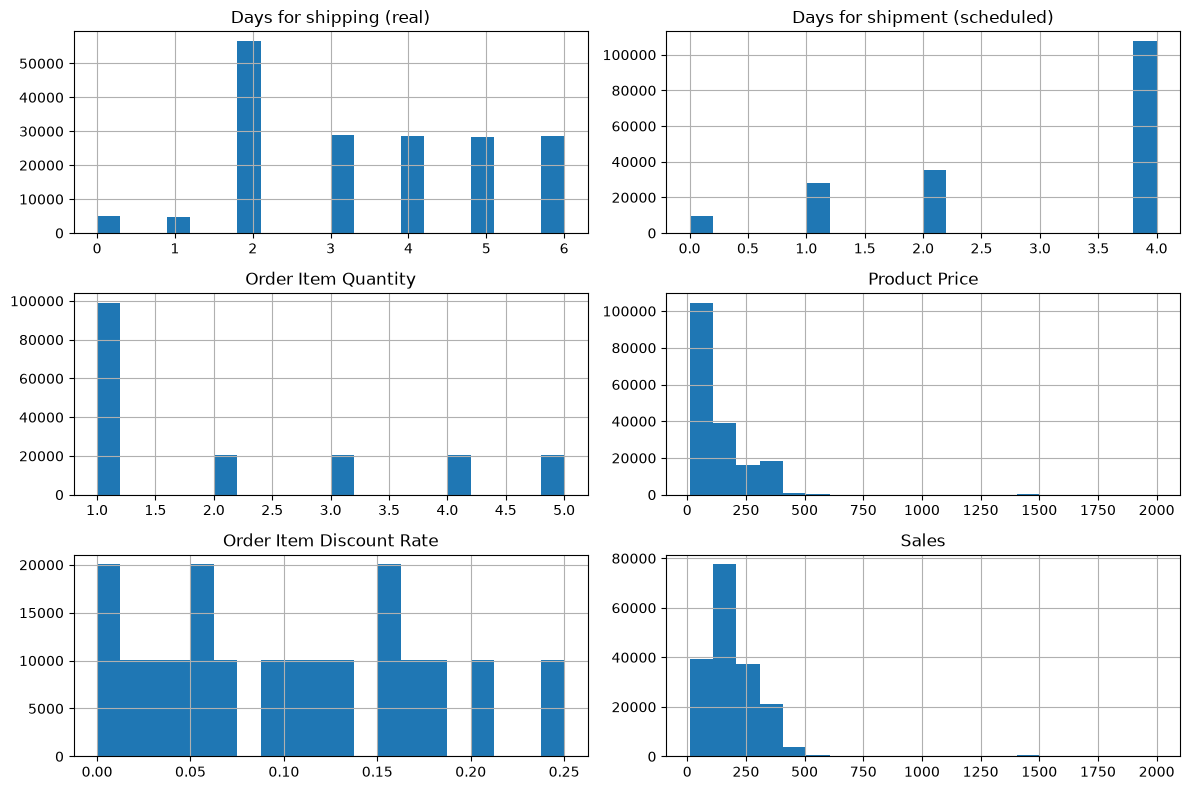

In [11]:
df[["Days for shipping (real)", "Days for shipment (scheduled)", "Order Item Quantity", "Product Price", "Order Item Discount Rate", "Sales"]].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

### Revisión de fuga de información (data leakage)

Algunas columnas solo se conocen **después** de que el pedido fue enviado o entregado. Si se usan, el modelo aprende la respuesta y las métricas no reflejan la realidad.

In [12]:
pd.crosstab(df["Delivery Status"], df["Late_delivery_risk"])

Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


In [13]:
retraso = df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
print("Coincidencia entre (real > programado) y Late_delivery_risk:", round(((retraso > 0).astype(int) == df["Late_delivery_risk"]).mean(), 4))

Coincidencia entre (real > programado) y Late_delivery_risk: 0.9755


In [14]:
print("Benefit per order == Order Profit Per Order:", (df["Benefit per order"] == df["Order Profit Per Order"]).all())
print("Sales per customer == Order Item Total:", (df["Sales per customer"] == df["Order Item Total"]).all())
print("Product Price == Order Item Product Price:", (df["Product Price"] == df["Order Item Product Price"]).all())
print("Customer Id == Order Customer Id:", (df["Customer Id"] == df["Order Customer Id"]).all())
print(df.groupby("Shipping Mode")["Days for shipment (scheduled)"].unique())

Benefit per order == Order Profit Per Order: True
Sales per customer == Order Item Total: True
Product Price == Order Item Product Price: True
Customer Id == Order Customer Id: True
Shipping Mode
First Class       [1]
Same Day          [0]
Second Class      [2]
Standard Class    [4]
Name: Days for shipment (scheduled), dtype: object


**Conclusiones:**
- `Delivery Status` determina directamente la variable objetivo ("Late delivery" = 1), por lo que se descarta.
- `Days for shipping (real)` y `shipping date` se conocen solo después del envío, por lo que se descartan.
- Hay columnas duplicadas, constantes (`Customer Email`, `Customer Password`, `Product Status`), vacías (`Product Description`) e identificadores sin valor predictivo.
- `Days for shipment (scheduled)` depende solo de `Shipping Mode`, así que es redundante.
- `Shipping Mode` es la variable más influyente: First Class llega tarde en el 95% de los casos.

## 2. Ingeniería de datos (preparación)

Se usan únicamente variables disponibles **al momento de registrar el pedido**.

In [15]:
df["order_date"] = pd.to_datetime(df["order date (DateOrders)"])
df["order_month"] = df["order_date"].dt.month
df["order_day_of_week"] = df["order_date"].dt.day_of_week
df["order_hour"] = df["order_date"].dt.hour
df[["order date (DateOrders)", "order_month", "order_day_of_week", "order_hour"]].head()

,order date (DateOrders),order_month,order_day_of_week,order_hour
0,1/31/2018 22:56,1,2,22
1,1/13/2018 12:27,1,5,12
2,1/13/2018 12:06,1,5,12
3,1/13/2018 11:45,1,5,11
4,1/13/2018 11:24,1,5,11


In [16]:
renombrar = {
    "Type": "payment_type",
    "Shipping Mode": "shipping_mode",
    "Market": "market",
    "Order Region": "order_region",
    "Order Country": "order_country",
    "Customer Segment": "customer_segment",
    "Category Name": "category_name",
    "Order Item Quantity": "quantity",
    "Product Price": "product_price",
    "Order Item Discount Rate": "discount_rate",
    "Late_delivery_risk": "late_delivery_risk",
}
datos = df.rename(columns=renombrar)

columnas_categoricas = ["payment_type", "shipping_mode", "market", "order_region", "order_country", "customer_segment", "category_name"]
columnas_numericas = ["quantity", "product_price", "discount_rate", "order_month", "order_day_of_week", "order_hour"]
columnas = columnas_categoricas + columnas_numericas
objetivo = "late_delivery_risk"

datos = datos[columnas + [objetivo]]
print(datos.shape)
print(datos.isnull().sum().sum(), "nulos")
datos.head()

(180519, 14)
0 nulos


,payment_type,shipping_mode,market,order_region,order_country,customer_segment,category_name,quantity,product_price,discount_rate,order_month,order_day_of_week,order_hour,late_delivery_risk
0,DEBIT,Standard Class,Pacific Asia,Southeast Asia,Indonesia,Consumer,Sporting Goods,1,327.75,0.04,1,2,22,0
1,TRANSFER,Standard Class,Pacific Asia,South Asia,India,Consumer,Sporting Goods,1,327.75,0.05,1,5,12,1
2,CASH,Standard Class,Pacific Asia,South Asia,India,Consumer,Sporting Goods,1,327.75,0.06,1,5,12,0
3,DEBIT,Standard Class,Pacific Asia,Oceania,Australia,Home Office,Sporting Goods,1,327.75,0.07,1,5,11,0
4,PAYMENT,Standard Class,Pacific Asia,Oceania,Australia,Corporate,Sporting Goods,1,327.75,0.09,1,5,11,0


In [17]:
columnas_fuga = ["Delivery Status", "Days for shipping (real)", "shipping date (DateOrders)"]
assert not any(c in datos.columns for c in columnas_fuga), "Hay columnas con fuga de información"
print("Control de calidad OK: no hay columnas con fuga de información")

Control de calidad OK: no hay columnas con fuga de información


In [18]:
datos[columnas_categoricas].nunique()

payment_type          4
shipping_mode         4
market                5
order_region         23
order_country       164
customer_segment      3
category_name        50
dtype: int64

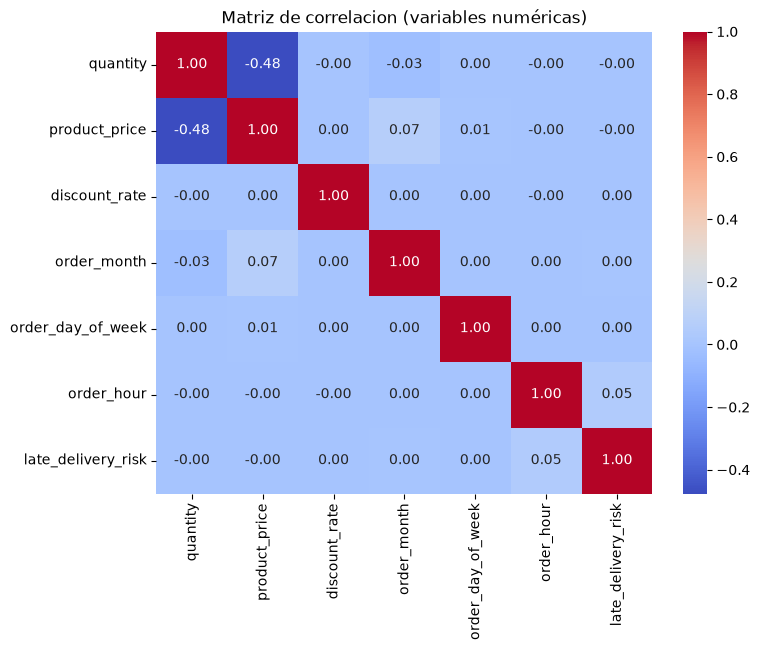

In [19]:
correlacion = datos[columnas_numericas + [objetivo]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlacion (variables numéricas)")
plt.show()

In [20]:
X = datos[columnas]
y = datos[objetivo]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(144415, 13) (36104, 13)


In [21]:
preprocesador = ColumnTransformer([
    ("categoricas", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False), columnas_categoricas),
    ("numericas", StandardScaler(), columnas_numericas),
])

## 3. Ingeniería del modelo

Se comparan tres algoritmos con validación cruzada (5 folds) sobre el conjunto de entrenamiento. El modelo base es predecir siempre la clase mayoritaria.

In [22]:
print("Accuracy del modelo base (clase mayoritaria):", round(y_test.value_counts(normalize=True).max(), 4))

Accuracy del modelo base (clase mayoritaria): 0.5483


In [23]:
modelos = {
    "Regresion Logistica": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = {}
for nombre, modelo in modelos.items():
    pipeline = Pipeline([("preprocesador", preprocesador), ("modelo", modelo)])
    puntajes = cross_val_score(pipeline, X_train, y_train, cv=folds, scoring="f1", n_jobs=-1)
    resultados[nombre] = puntajes
    print(f"{nombre}: F1 = {puntajes.mean():.4f} (+/- {puntajes.std():.4f})")

Regresion Logistica: F1 = 0.6794 (+/- 0.0026)


Random Forest: F1 = 0.6957 (+/- 0.0019)


Gradient Boosting: F1 = 0.6986 (+/- 0.0024)


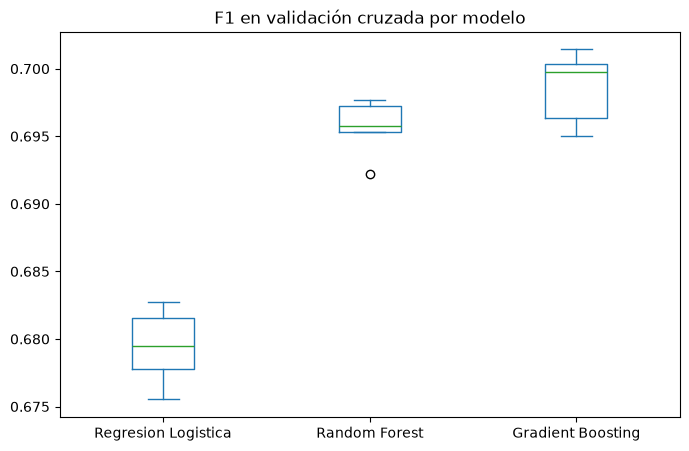

In [24]:
pd.DataFrame(resultados).plot(kind="box", figsize=(8, 5), title="F1 en validación cruzada por modelo")
plt.show()

Se elige **Gradient Boosting (HistGradientBoostingClassifier)** por tener el mejor F1 en validación cruzada y ser rápido de entrenar, lo que facilita el re-entrenamiento desde la API. Se ajustan sus hiperparámetros con GridSearchCV.

In [25]:
pipeline = Pipeline([("preprocesador", preprocesador), ("modelo", HistGradientBoostingClassifier(random_state=42))])
parametros = {
    "modelo__learning_rate": [0.05, 0.1, 0.2],
    "modelo__max_iter": [200, 400],
    "modelo__max_depth": [None, 10],
    "modelo__l2_regularization": [0.0, 1.0],
}
grid = GridSearchCV(pipeline, parametros, cv=3, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Mejores parametros:", grid.best_params_)
print("Mejor F1 en validacion cruzada:", round(grid.best_score_, 4))

Mejores parametros: {'modelo__l2_regularization': 1.0, 'modelo__learning_rate': 0.2, 'modelo__max_depth': None, 'modelo__max_iter': 400}
Mejor F1 en validacion cruzada: 0.7124


In [26]:
mejor_modelo = grid.best_estimator_
y_pred = mejor_modelo.predict(X_test)
y_prob = mejor_modelo.predict_proba(X_test)[:, 1]

## 4. Evaluación del modelo

In [27]:
metricas = {
    "accuracy": round(accuracy_score(y_test, y_pred), 4),
    "precision": round(precision_score(y_test, y_pred), 4),
    "recall": round(recall_score(y_test, y_pred), 4),
    "f1_score": round(f1_score(y_test, y_pred), 4),
    "roc_auc": round(roc_auc_score(y_test, y_prob), 4),
}
for nombre, valor in metricas.items():
    print(f"{nombre}: {valor}")
print(classification_report(y_test, y_pred, target_names=["A tiempo", "Tardía"]))

accuracy: 0.7394
precision: 0.8335
recall: 0.6557
f1_score: 0.734
roc_auc: 0.8284
              precision    recall  f1-score   support

    A tiempo       0.67      0.84      0.74     16308
      Tardía       0.83      0.66      0.73     19796

    accuracy                           0.74     36104
   macro avg       0.75      0.75      0.74     36104
weighted avg       0.76      0.74      0.74     36104



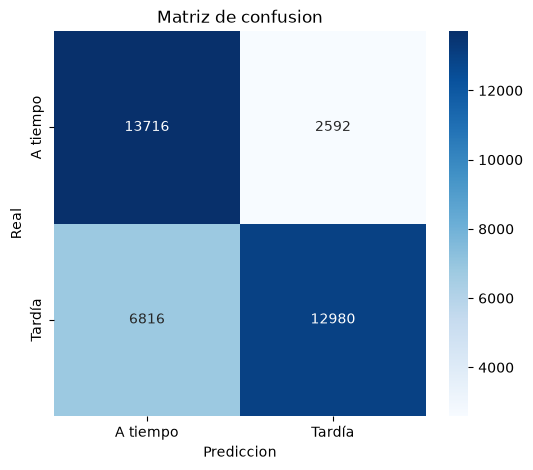

In [28]:
matriz = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=["A tiempo", "Tardía"], yticklabels=["A tiempo", "Tardía"])
plt.xlabel("Prediccion")
plt.ylabel("Real")
plt.title("Matriz de confusion")
plt.show()

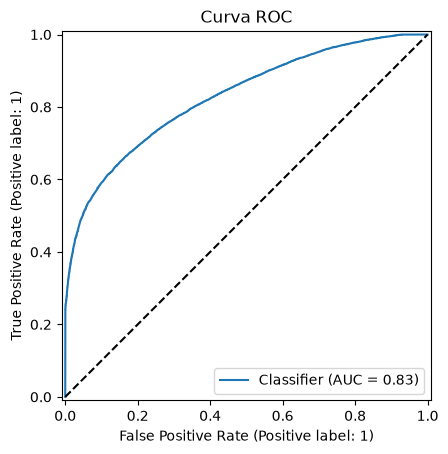

In [29]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0, 1], [0, 1], "k--")
plt.title("Curva ROC")
plt.show()

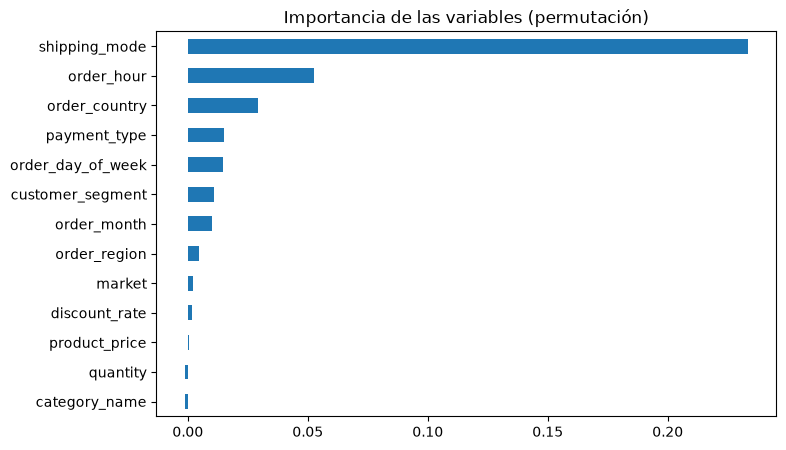

In [30]:
from sklearn.inspection import permutation_importance
muestra = X_test.sample(5000, random_state=42)
importancia = permutation_importance(mejor_modelo, muestra, y_test.loc[muestra.index], scoring="f1", n_repeats=5, random_state=42, n_jobs=-1)
importancia = pd.Series(importancia.importances_mean, index=columnas).sort_values()
importancia.plot(kind="barh", figsize=(8, 5), title="Importancia de las variables (permutación)")
plt.show()

In [31]:
assert metricas["accuracy"] > 0.70 and metricas["f1_score"] > 0.70 and metricas["roc_auc"] > 0.80, "El modelo no cumple el criterio de calidad"
print("Control de calidad OK: el modelo cumple el criterio de éxito definido")

Control de calidad OK: el modelo cumple el criterio de éxito definido


## 5. Despliegue: exportación del modelo

Se guarda el pipeline completo (preprocesamiento + modelo), sus métricas y los valores válidos de cada variable categórica. El servicio de IA (FastAPI) carga estos archivos para predecir y el frontend usa las opciones para construir el formulario.

In [32]:
os.makedirs("../backend/model", exist_ok=True)
joblib.dump(mejor_modelo, "../backend/model/modelo.joblib")

informacion = {
    "version": 1,
    "algoritmo": "HistGradientBoostingClassifier",
    "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds"),
    "registros_entrenamiento": len(X_train),
    "registros_prueba": len(X_test),
    "mejores_parametros": {k.replace("modelo__", ""): v for k, v in grid.best_params_.items()},
    "metricas": metricas,
    "matriz_confusion": matriz.tolist(),
    "columnas_categoricas": columnas_categoricas,
    "columnas_numericas": columnas_numericas,
    "opciones": {c: sorted(datos[c].unique().tolist()) for c in columnas_categoricas},
}
with open("../backend/model/metricas.json", "w", encoding="utf-8") as archivo:
    json.dump(informacion, archivo, ensure_ascii=False, indent=2)
print("Modelo y métricas exportados")

Modelo y métricas exportados


In [33]:
modelo_cargado = joblib.load("../backend/model/modelo.joblib")
ejemplo = pd.DataFrame([{
    "payment_type": "DEBIT",
    "shipping_mode": "First Class",
    "market": "LATAM",
    "order_region": "South America",
    "order_country": "Brasil",
    "customer_segment": "Consumer",
    "category_name": "Cleats",
    "quantity": 2,
    "product_price": 59.99,
    "discount_rate": 0.05,
    "order_month": 6,
    "order_day_of_week": 2,
    "order_hour": 14,
}])
print("Prediccion:", modelo_cargado.predict(ejemplo)[0])
print("Probabilidad de entrega tardía:", round(modelo_cargado.predict_proba(ejemplo)[0, 1], 4))

Prediccion: 1
Probabilidad de entrega tardía: 0.9998


## 6. Monitoreo y mantenimiento

- Cada predicción realizada por la API se guarda en la base de datos (datos enviados, resultado, probabilidad y versión del modelo).
- El endpoint de re-entrenamiento vuelve a ejecutar los pasos 2 a 4 con los datos actualizados, genera una nueva versión del modelo y registra sus métricas.
- El modelo nuevo solo reemplaza al actual si cumple el mismo criterio de calidad definido en la fase 1.